In [70]:
import sys
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [71]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.5,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=80,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [72]:
def radial_stretch_from_point(img, stretch_factor, center):
    h, w = img.shape[:2]
    cx, cy = center

    # pixel grid
    y, x = np.indices((h, w), dtype=np.float32)

    # shift relative to chosen center
    dx = x - cx
    dy = y - cy

    # scale vectors
    scale = 1 / stretch_factor

    map_x = (cx + dx * scale).astype(np.float32)
    map_y = (cy + dy * scale).astype(np.float32)
    
    stretched = cv2.remap(
        img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return stretched

In [73]:
y, x = np.meshgrid(
    np.arange(460, 500),
    np.arange(460, 500),
    indexing="ij"
)

indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

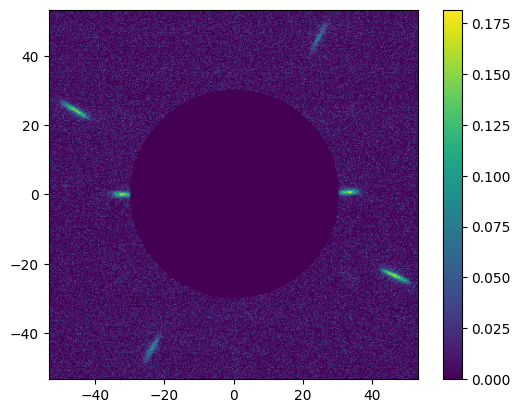

In [74]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_05offset.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits') #taken using jupyter
img = ADC.crop_image(fieldcube[0])
imshow_field(img)
plt.colorbar()

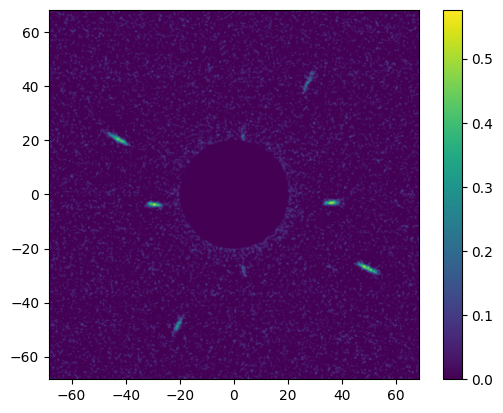

In [ ]:
img = fieldcube[26]
img = img/img.max()

hp = ADC.hpf(img,20)
hp = hp - ADC.hpf(hp,0.9)
hp[hp < 0] = 0
plt.figure()
imshow_field(hp)
plt.colorbar()

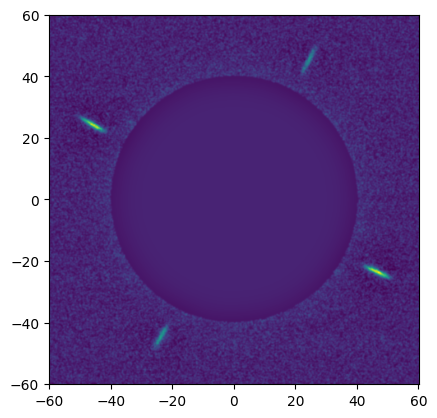

In [76]:
img = fieldcube[26]
img = ADC.crop_image(img,extent=450,mask_diam=80)
hp = ADC.hpf(img,20)
hp = hp - ADC.hpf(hp,0.8)
imshow_field(hp)
plt.show()


psf = np.array(hp.shaped)


center = psf.shape[0]/2
search_size = 50
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

(np.int64(33), np.int64(12))
est radiation center at pixel index [[200. 212.]
 [200. 233.]]


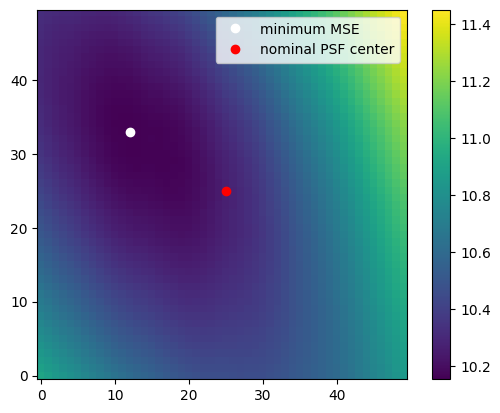

In [77]:
Z = np.array(Z)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)

rad_center = np.array([indices[a[1]],indices[a[0]]])
print(f'est radiation center at pixel index {rad_center}')

Z = np.reshape(Z,y.shape)
plt.imshow(Z,origin='lower')
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.plot(search_size/2,search_size/2,'o',color='red',label='nominal PSF center')
plt.legend()
plt.colorbar()

In [82]:
#now go through some of the dataset and look at the variance
center = img.shaped.shape[0]/2
search_size = 64
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z_cube = []
rel_rad_centers = []

for i, field in enumerate(fieldcube):
    img = ADC.crop_image(field,mask_diam=80,extent=480)
    hp = ADC.hpf(img,20)
    hp = hp - ADC.hpf(hp,0.8)
    # a = ADC.all_speckle_angles(img,speckle_filter=True)
    # speckle_list.append(a)
    # diffs13_list.append(a[0] - a[2])
    # diffs24_list.append(a[1] - a[3])

    Z = []
    psf = np.array(hp.shaped)
    for index in indices:
        psf_stretched = radial_stretch_from_point(psf,1.05,center=index)
        mse = np.sum((psf - psf_stretched)**2)
        Z.append(mse)

    Z = np.array(Z)
    a = np.unravel_index(Z.argmin(),y.shape)
    rel_rad_centers.append(a)

    Z_cube.append(np.reshape(Z,y.shape))

rel_rad_centers = np.array(rel_rad_centers)
rel_rad_centers = rel_rad_centers - search_size/2

[  1. -10.]


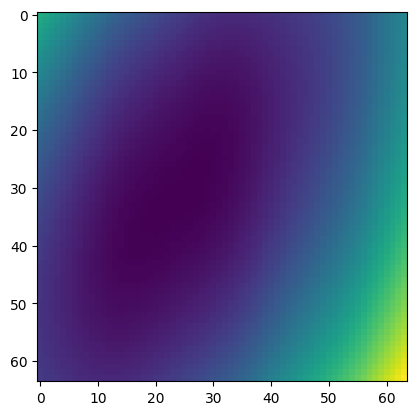

In [83]:
n = 50
plt.imshow(Z_cube[n])
print(rel_rad_centers[n])

Text(0.5, 1.0, 'Stretch Factor 1.05')

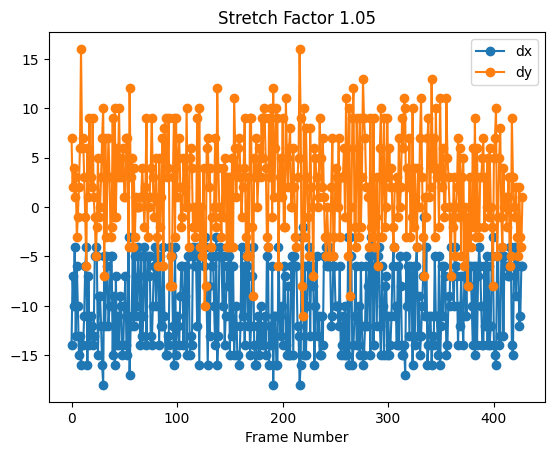

In [86]:

plt.plot(rel_rad_centers[:,1],'o-',label='dx')
plt.plot(rel_rad_centers[:,0],'o-',label='dy')
plt.legend()
plt.xlabel('Frame Number')
plt.title('Stretch Factor 1.05')

In [87]:
mx = np.mean(rel_rad_centers[:,1])
sx = np.std(rel_rad_centers[:,1])

my = np.mean(rel_rad_centers[:,0])
sy = np.std(rel_rad_centers[:,0])

print(f'mean of dx (pixels): {mx}')
print(f'sd of dx (pixels): {sx}\n')
print(f'sd of dy (pixels): {sy}')
print(f'mean of dy (pixels): {my}')

mean of dx (pixels): -9.766355140186915
sd of dx (pixels): 4.231235517519271

sd of dy (pixels): 4.979028427384779
mean of dy (pixels): 2.149532710280374
